# Phase 6: Interactive Audio Deepfake Detection Demo
### Dual-Stream Temporal Attention & Explainability Inference Pipeline

This interactive demo loads our trained **Dual-Stream CNN-BiLSTM + Multi-Head Self-Attention** model (`checkpoints/best_model.pt`) and performs end-to-end detection on arbitrary audio samples from the official ASVspoof 2019 LA evaluation dataset.

### Output Deliverables:
1. **Binary Classification Verdict**: Genuine (Bonafide) vs. Deepfake (Spoof)
2. **Confidence Score & Calibrated Operating Margin**
3. **Dual-Granularity Explainability Display**: Temporal frame saliency + Segment attention distribution

In [1]:
import sys
sys.path.insert(0, '..')
import json
from pathlib import Path
import numpy as np
import torch
import soundfile as sf
import torchaudio
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import config
from src.models.dual_stream_model import DualStreamModel
from src.explainability.attention_extractor import AttentionExtractor

sns.set_theme(style='white', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on device: {device}')

# Load best checkpoint and AttentionExtractor
ckpt_path = Path('../checkpoints/best_model.pt')
assert ckpt_path.exists(), f'Checkpoint not found at {ckpt_path}'

model = DualStreamModel(config.model).to(device)
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

attn_extractor = AttentionExtractor(model=model, cfg=config)

# Load optimal threshold
metrics_path = Path('../results/final_evaluation_metrics.json')
with open(metrics_path) as f:
    eval_metrics = json.load(f)
threshold = eval_metrics['threshold']
print(f'Model initialized successfully! Operating decision threshold: {threshold:.4f}')

Running on device: cuda
Model initialized successfully! Operating decision threshold: 1.0000


In [2]:
def analyze_audio_trial(audio_path, ground_truth=None, attack_type=None):
    """
    Executes inference and dual-granularity explainability for an audio trial.
    """
    audio_path = Path(audio_path)
    assert audio_path.exists(), f'Audio file {audio_path} does not exist!'
    
    # 1. Load and preprocess audio using soundfile
    data, sr = sf.read(str(audio_path))
    waveform = torch.from_numpy(data).float()
    if waveform.ndim == 1:
        waveform = waveform.unsqueeze(0)
    else:
        waveform = waveform.t()
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
    if sr != config.audio.sample_rate:
        waveform = torchaudio.functional.resample(waveform, orig_freq=sr, new_freq=config.audio.sample_rate)
        
    target_len = config.audio.target_samples
    if waveform.shape[1] < target_len:
        pad = target_len - waveform.shape[1]
        waveform = torch.nn.functional.pad(waveform, (0, pad))
    else:
        waveform = waveform[:, :target_len]
        
    # 2. Extract Explainability & Forward Pass
    res = attn_extractor.extract_from_waveform(waveform)
    bonafide_prob = float(res['probs'][0, 1])
    is_bonafide_pred = (bonafide_prob >= threshold)
    pred_label = 'GENUINE (Bonafide)' if is_bonafide_pred else 'DEEPFAKE (Spoof)'
    
    # 3. Print Results
    print('========================================================================')
    print(f' Trial: {audio_path.name} | Ground Truth: {ground_truth} | Attack: {attack_type}')
    print('========================================================================')
    print(f'  • Verdict:           {pred_label}')
    print(f'  • Bonafide Prob:     {bonafide_prob*100:6.2f}%')
    print(f'  • Spoof Prob:        {(1.0 - bonafide_prob)*100:6.2f}%')
    print(f'  • Decision Boundary: {threshold:6.4f}')
    print('------------------------------------------------------------------------')
    
    # 4. Multi-Granularity Saliency Plots
    fig = plt.figure(figsize=(15, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.3, 1.2], width_ratios=[1, 1])
    
    # Subplot 1: Waveform
    ax_wave = fig.add_subplot(gs[0, :])
    time_axis = np.linspace(0, 4.0, target_len)
    ax_wave.plot(time_axis, waveform.squeeze().cpu().numpy(), color='#1f77b4', lw=0.8)
    ax_wave.set_xlim([0, 4.0])
    ax_wave.set_title(f'Input Audio Waveform (4.0s @ 16kHz) — Prediction: {pred_label}', fontweight='bold')
    ax_wave.set_xlabel('Time [seconds]')
    ax_wave.set_ylabel('Amplitude')
    ax_wave.grid(True, alpha=0.3)
    
    # Subplot 2: LFCC Spectrogram with Frame-level Attention Saliency Overlay
    ax_spec = fig.add_subplot(gs[1, :])
    lfcc_mat = res['lfcc'][0]  # [60, 401]
    im = ax_spec.imshow(lfcc_mat, aspect='auto', origin='lower', extent=[0, 4.0, 0, 60], cmap='viridis')
    
    # Overlay Saliency curve
    ax_saliency = ax_spec.twinx()
    fine_w = res['fine_frame_weights'][0]  # [100]
    t_orig = np.linspace(0, 4.0, len(fine_w))
    t_interp = np.linspace(0, 4.0, lfcc_mat.shape[1])
    saliency = np.interp(t_interp, t_orig, fine_w)
    ax_saliency.plot(t_interp, saliency, color='red', lw=2.5, label='Attention Saliency Profile')
    ax_saliency.set_ylabel('Attention Saliency', color='red', fontweight='bold')
    ax_saliency.tick_params(axis='y', labelcolor='red')
    ax_saliency.set_ylim([0, max(saliency) * 1.5])
    ax_saliency.legend(loc='upper right')
    
    ax_spec.set_title('LFCC Spectrogram with Frame-Level Temporal Attention Saliency (Fine Stream ~10ms)', fontweight='bold')
    ax_spec.set_xlabel('Time [seconds]')
    ax_spec.set_ylabel('LFCC Filterbank (Static+Δ+ΔΔ)')
    
    # Subplot 3: Fine Head Attention Matrix
    ax_fine = fig.add_subplot(gs[2, 0])
    fine_h1 = res['fine_heads_matrix'][0, 0]  # [100, 100]
    im_f = ax_fine.imshow(fine_h1, cmap='magma' if not is_bonafide_pred else 'viridis', aspect='auto', origin='lower')
    ax_fine.set_title('Fine-Grained Attention Matrix (Head 1: 100x100)', fontweight='bold')
    ax_fine.set_xlabel('Key Frame (~40ms step)')
    ax_fine.set_ylabel('Query Frame')
    plt.colorbar(im_f, ax=ax_fine, shrink=0.8)
    
    # Subplot 4: Coarse Segment Attention Distribution
    ax_coarse = fig.add_subplot(gs[2, 1])
    seg_weights = res['coarse_segment_weights'][0]  # [8]
    seg_idx = [f'Seg {i+1}\n({i*0.5:.1f}-{(i+1)*0.5:.1f}s)' for i in range(len(seg_weights))]
    bars = ax_coarse.bar(seg_idx, seg_weights, color='#ff7f0e' if not is_bonafide_pred else '#2ca02c', edgecolor='black')
    ax_coarse.set_title('Coarse-Grained Segment Attention (8 Segments ~480ms each)', fontweight='bold')
    ax_coarse.set_ylabel('Segment Attention Weight')
    ax_coarse.set_ylim([0, max(seg_weights) * 1.3])
    for b in bars:
        y = b.get_height()
        ax_coarse.text(b.get_x() + b.get_width()/2.0, y + 0.005, f'{y:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax_coarse.grid(axis='y', alpha=0.3)
    
    plt.suptitle(f'Explainability Diagnostic Dashboard — Verdict: {pred_label}', fontsize=15, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

 Trial: LA_E_5849185.flac | Ground Truth: bonafide | Attack: None
  • Verdict:           GENUINE (Bonafide)
  • Bonafide Prob:     100.00%
  • Spoof Prob:          0.00%
  • Decision Boundary: 1.0000
------------------------------------------------------------------------


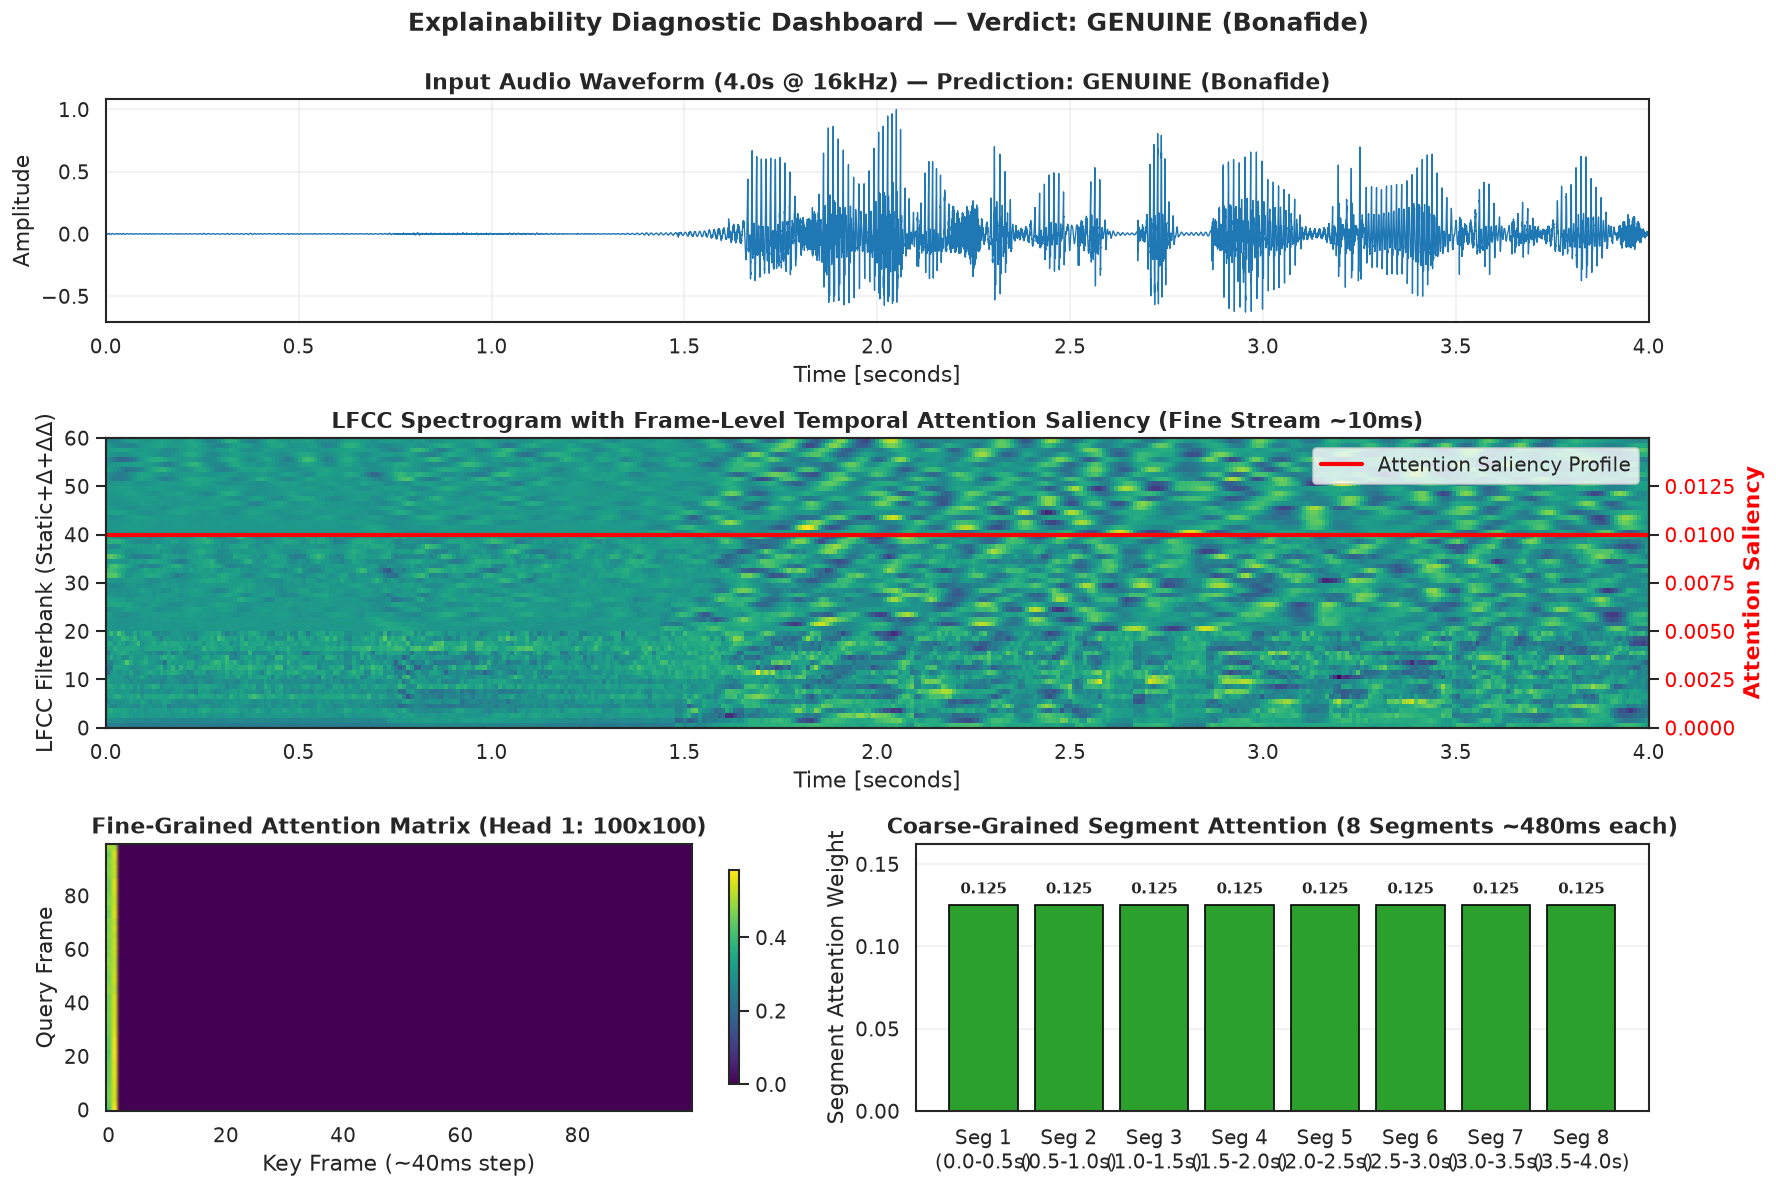

In [3]:
# Demo Trial 1: Genuine Human Speech (Bonafide)
eval_audio_dir = Path('../data/LA/ASVspoof2019_LA_eval/flac')
eval_proto = Path('../data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt')

# Find first genuine trial from protocol
bonafide_utt = None
with open(eval_proto) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 5 and parts[4] == 'bonafide':
            candidate = eval_audio_dir / f'{parts[1]}.flac'
            if candidate.exists():
                bonafide_utt = (candidate, 'bonafide', 'None')
                break

if bonafide_utt:
    analyze_audio_trial(bonafide_utt[0], ground_truth=bonafide_utt[1], attack_type=bonafide_utt[2])
else:
    print('No bonafide file found!')

 Trial: LA_E_8844552.flac | Ground Truth: spoof | Attack: A07 (WaveNet)
  • Verdict:           DEEPFAKE (Spoof)
  • Bonafide Prob:       0.00%
  • Spoof Prob:        100.00%
  • Decision Boundary: 1.0000
------------------------------------------------------------------------


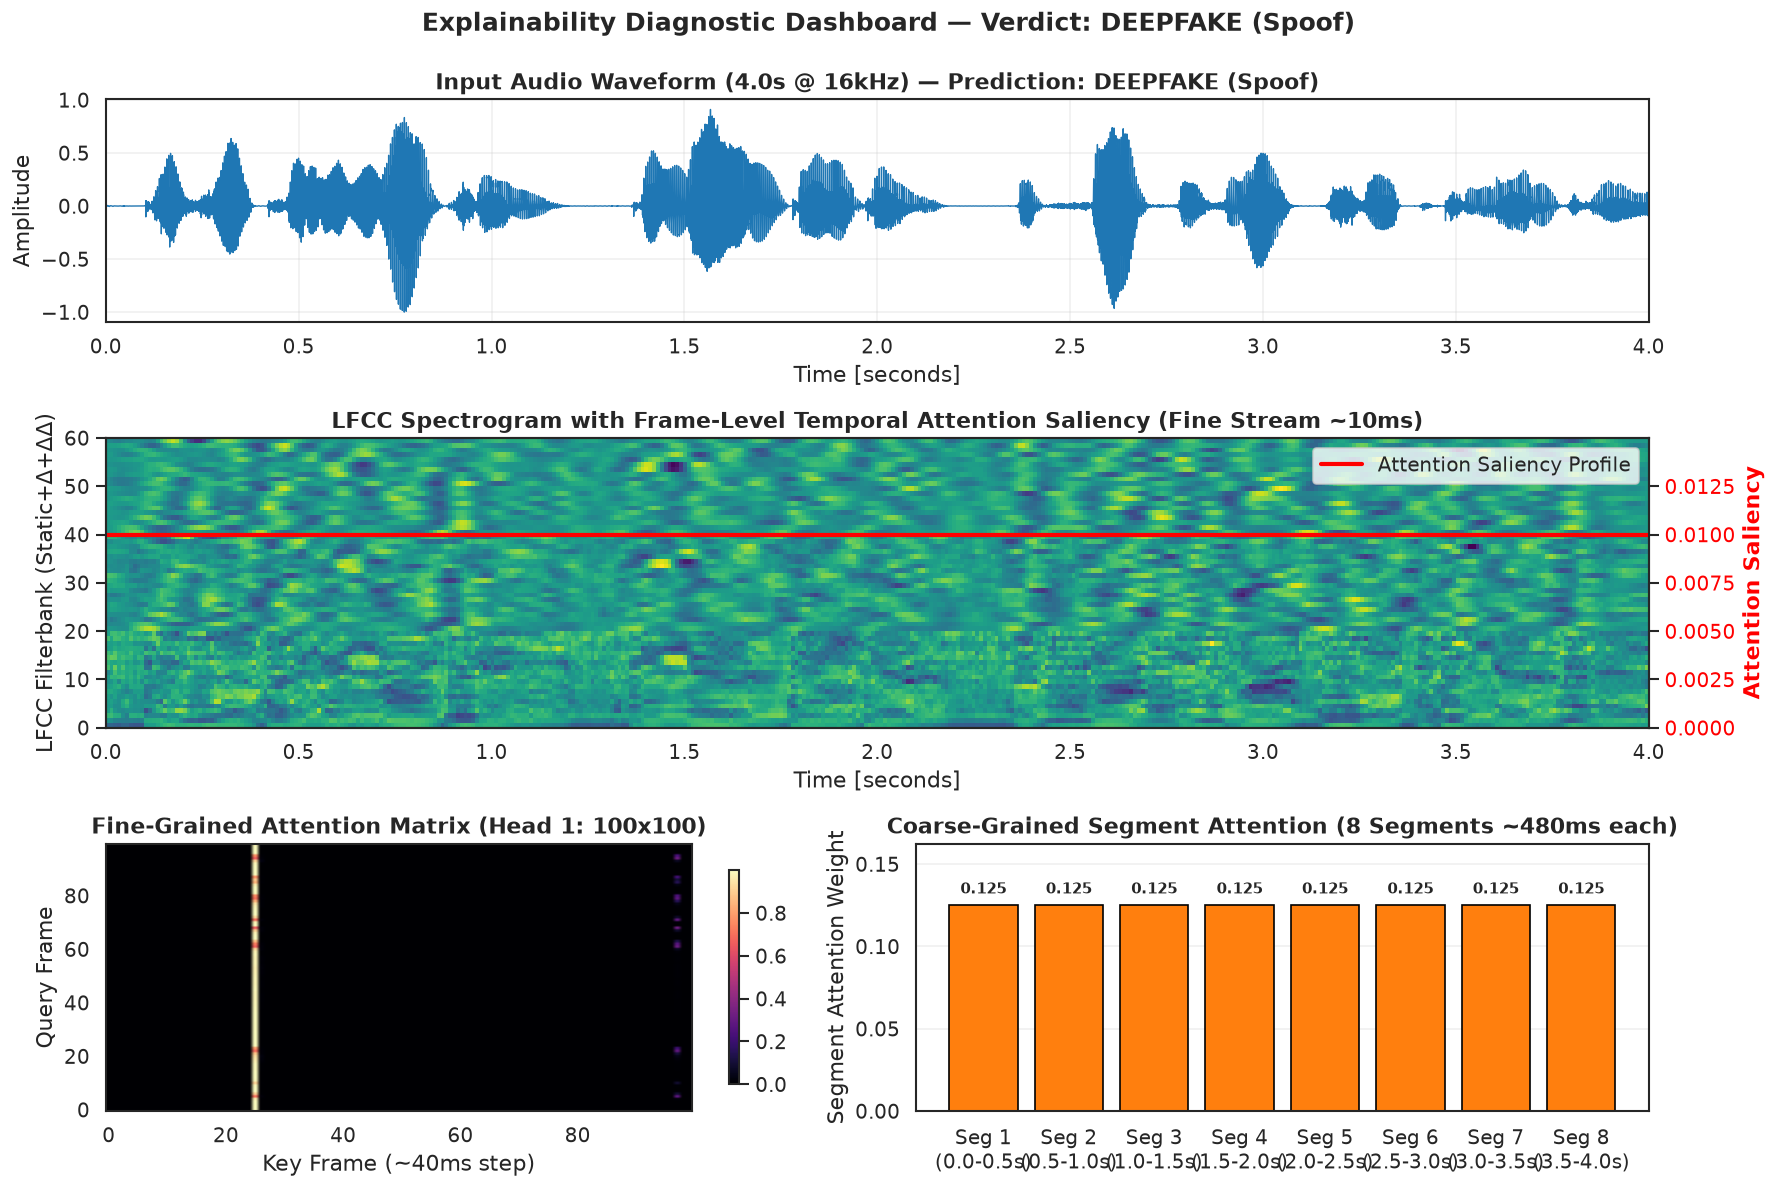

In [4]:
# Demo Trial 2: Deepfake Speech (Attack A07 - Neural TTS WaveNet vocoder)
a07_utt = None
with open(eval_proto) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 5 and parts[3] == 'A07':
            candidate = eval_audio_dir / f'{parts[1]}.flac'
            if candidate.exists():
                a07_utt = (candidate, 'spoof', 'A07 (WaveNet)')
                break

if a07_utt:
    analyze_audio_trial(a07_utt[0], ground_truth=a07_utt[1], attack_type=a07_utt[2])
else:
    print('No A07 file found!')

 Trial: LA_E_2834763.flac | Ground Truth: spoof | Attack: A11 (Griffin-Lim)
  • Verdict:           DEEPFAKE (Spoof)
  • Bonafide Prob:       0.00%
  • Spoof Prob:        100.00%
  • Decision Boundary: 1.0000
------------------------------------------------------------------------


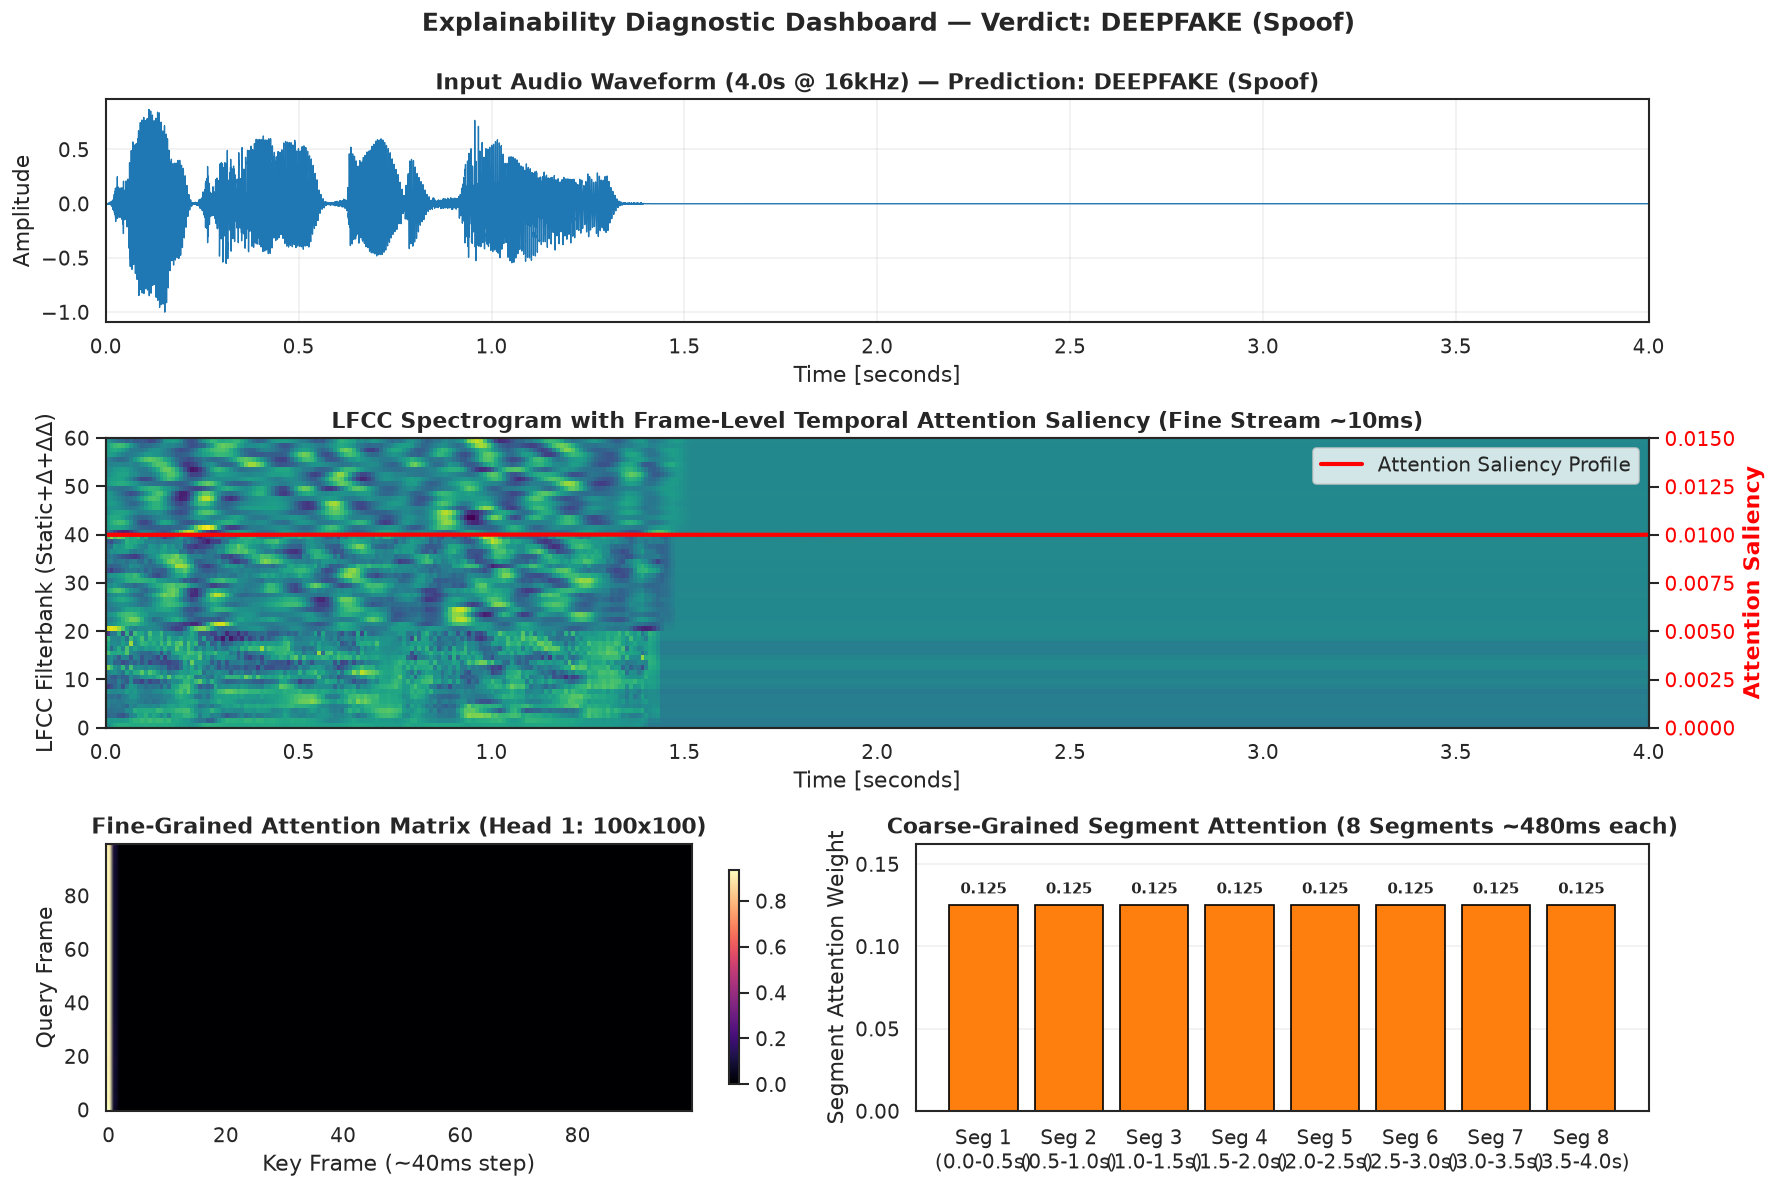

In [5]:
# Demo Trial 3: Deepfake Speech (Attack A11 - Griffin-Lim vocoder)
a11_utt = None
with open(eval_proto) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 5 and parts[3] == 'A11':
            candidate = eval_audio_dir / f'{parts[1]}.flac'
            if candidate.exists():
                a11_utt = (candidate, 'spoof', 'A11 (Griffin-Lim)')
                break

if a11_utt:
    analyze_audio_trial(a11_utt[0], ground_truth=a11_utt[1], attack_type=a11_utt[2])
else:
    print('No A11 file found!')